In [1]:
# -*- coding: utf-8 -*-
"""model_comparision.py
Model training + comparison + EDA + ensemble + model saving
No spatial grouping
"""

# ==========================================
# 1. INSTALL & IMPORT LIBRARIES
# ==========================================
!pip install openpyxl scikit-optimize shap xgboost joblib -q

import os
import gc
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from google.colab import drive

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, roc_auc_score, auc,
    precision_score, recall_score, f1_score
)
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 5.6 MB/s eta 0:00:00


Mounted at /content/drive

========================= GRID: 3x3 =========================

Shape: (1996, 10)
Class balance: [997 999]
Features: ['aspect', 'curvature', 'dis_to_fault', 'dis_to_river', 'dis_to_road', 'dis_to_thrust', 'ndvi', 'slope', 'twi']


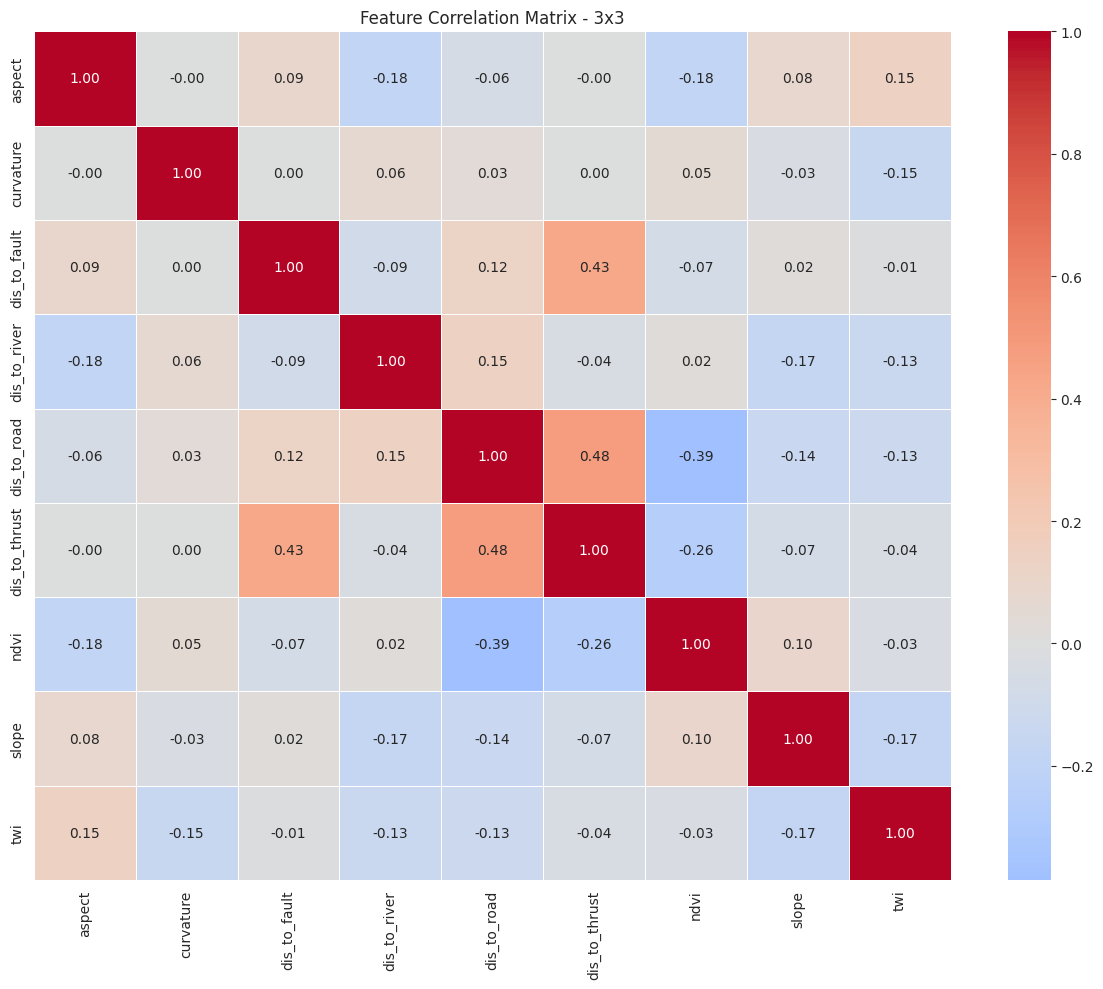

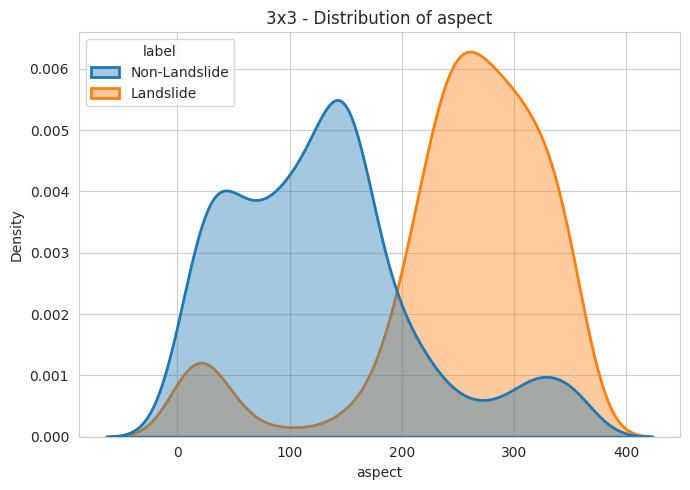

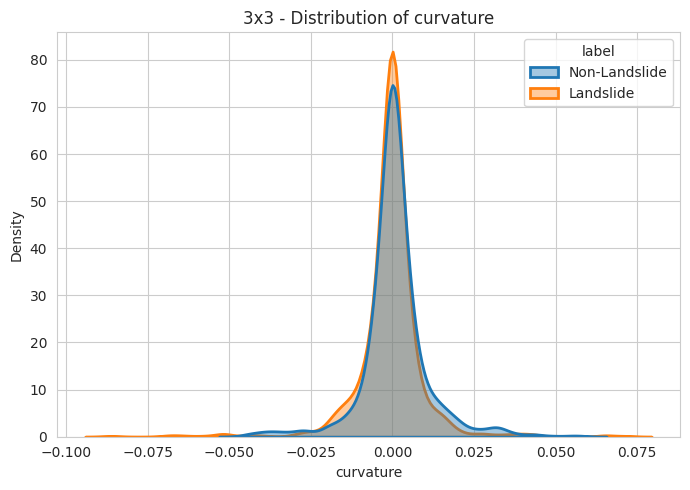

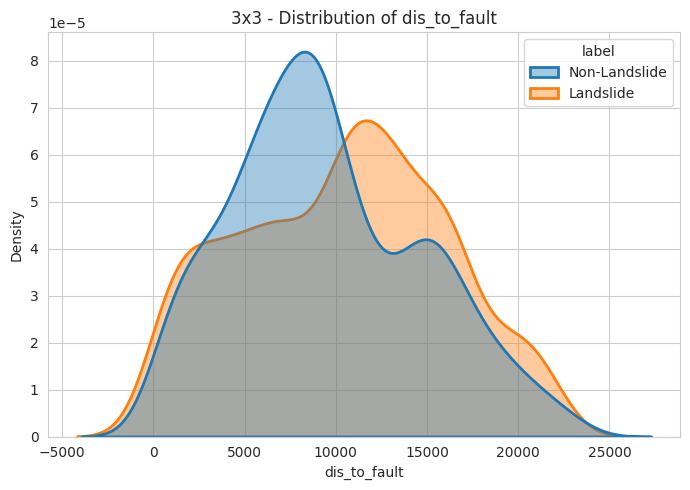

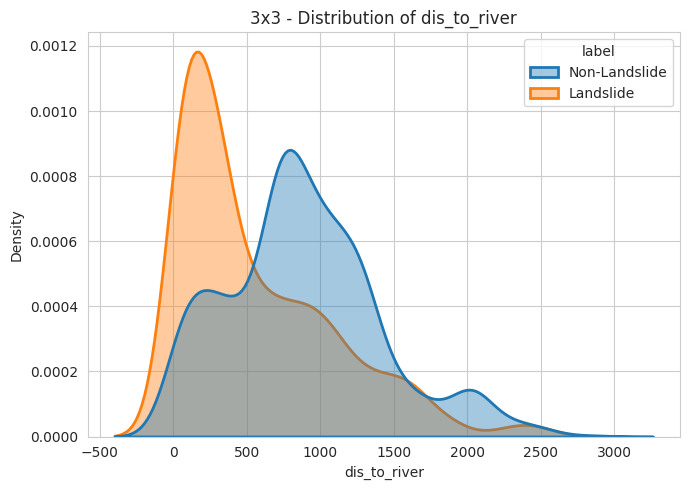

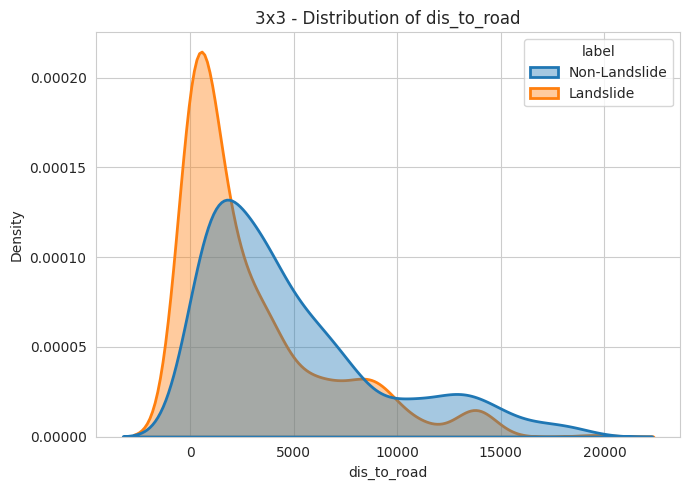

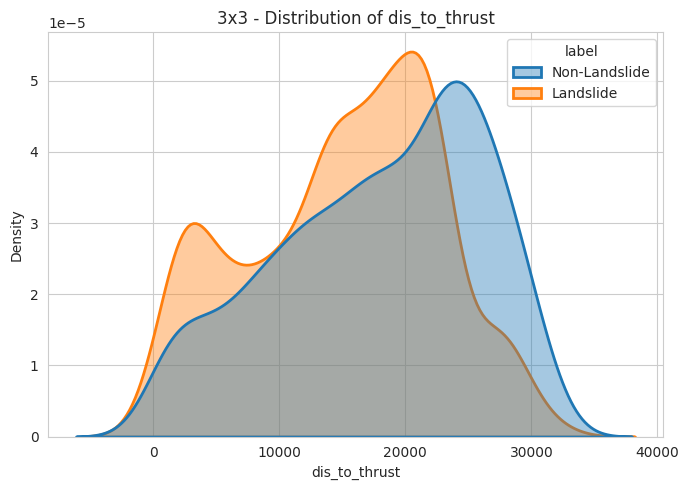

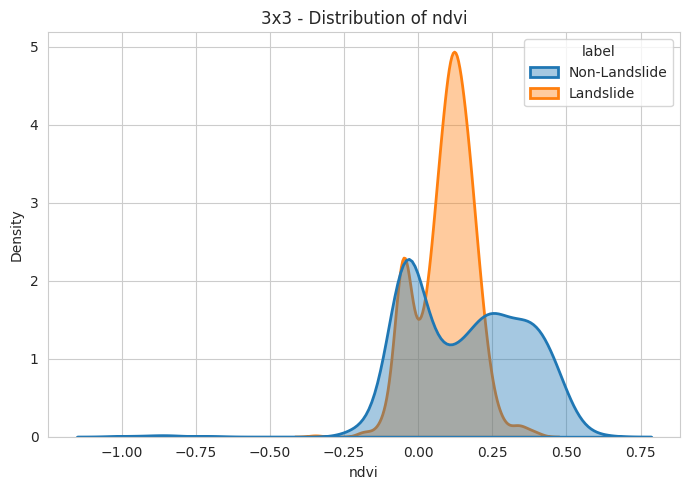

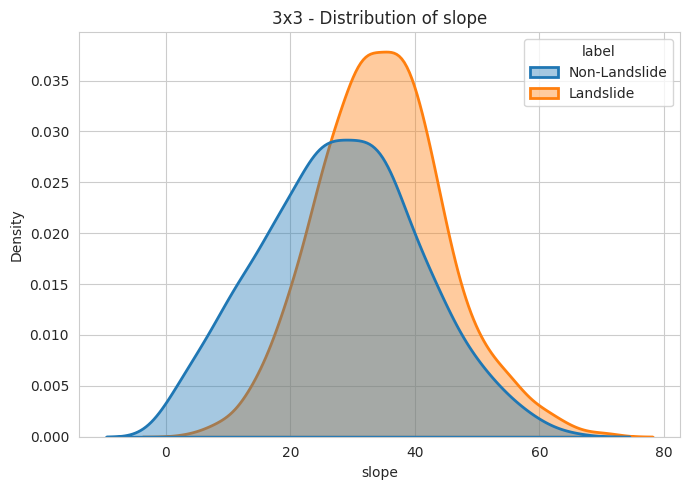

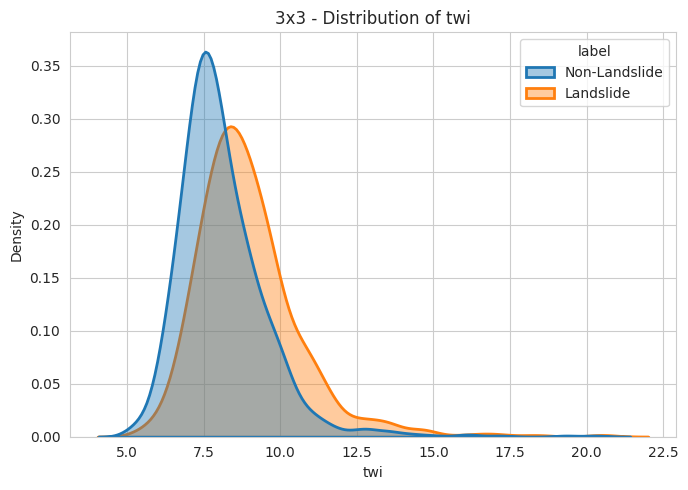


--------------- Training RF on 3x3 ---------------
    Actual  Predicted  Probability
0        1          1     0.986362
1        1          1     0.976607
2        0          0     0.028842
3        0          0     0.015434
4        0          0     0.019758
5        1          1     0.973604
6        0          0     0.017504
7        0          0     0.013815
8        1          0     0.331726
9        1          1     0.857456
10       1          1     0.934652
11       1          1     0.986820
12       1          1     0.569173
13       1          1     0.986728
14       1          1     0.982835
15       1          1     0.916985
16       1          1     0.970988
17       1          1     0.986259
18       1          1     0.975626
19       1          1     0.959498
RF Best Params: OrderedDict({'class_weight': 'balanced_subsample', 'max_depth': 25, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400})
RF Holdout Metrics: {'accuracy': 0.925, 'precision': 0.925, 

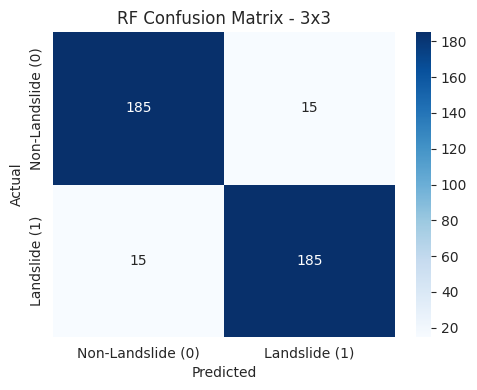

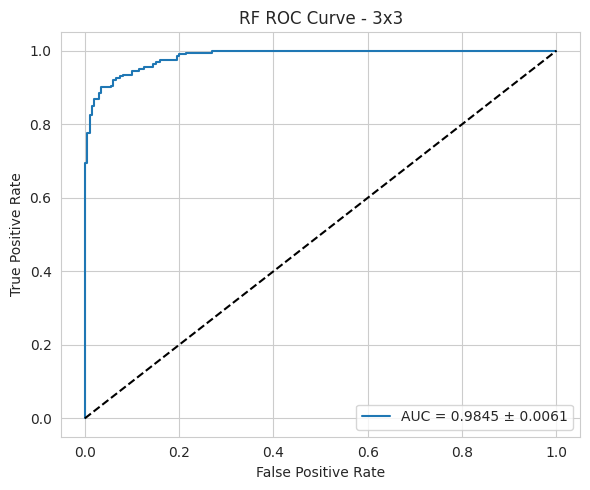

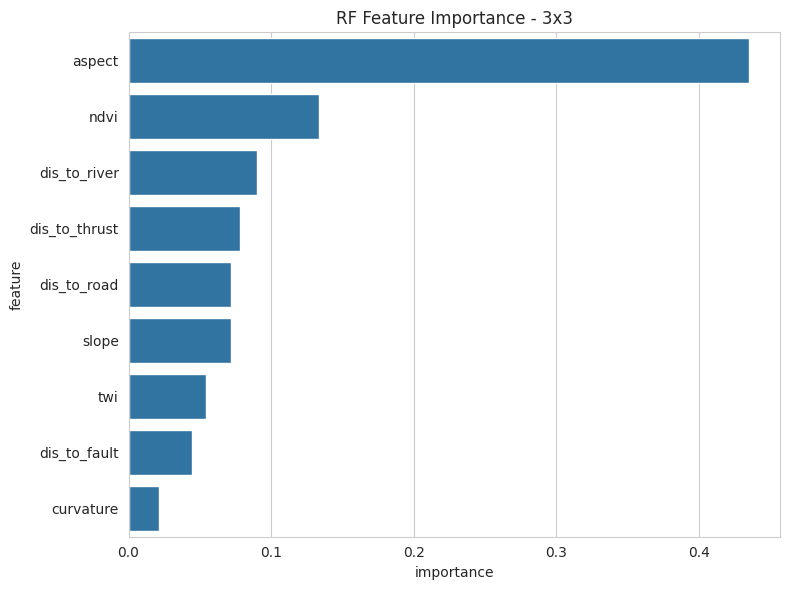

<Figure size 640x480 with 0 Axes>

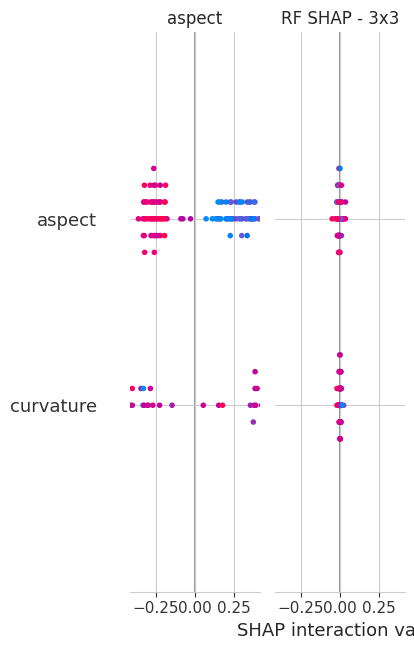


--------------- Training SVM on 3x3 ---------------
    Actual  Predicted  Probability
0        1          1     0.987047
1        1          1     0.894526
2        0          0     0.002639
3        0          0     0.002167
4        0          0     0.018134
5        1          1     0.602907
6        0          0     0.065150
7        0          0     0.019758
8        1          0     0.281095
9        1          1     0.715491
10       1          1     0.932417
11       1          1     0.978101
12       1          1     0.696488
13       1          1     0.992683
14       1          1     0.967431
15       1          1     0.857406
16       1          1     0.964323
17       1          1     0.989150
18       1          1     0.882332
19       1          1     0.793635
SVM Best Params: OrderedDict({'model__C': 12.183478599541608, 'model__gamma': 0.15388767743112713, 'model__kernel': 'rbf'})
SVM Holdout Metrics: {'accuracy': 0.9025, 'precision': 0.900497512437811, 'recall': 0.90

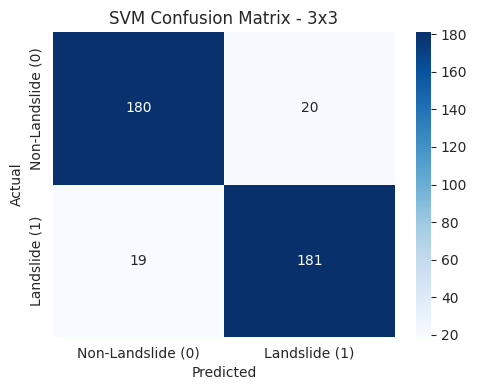

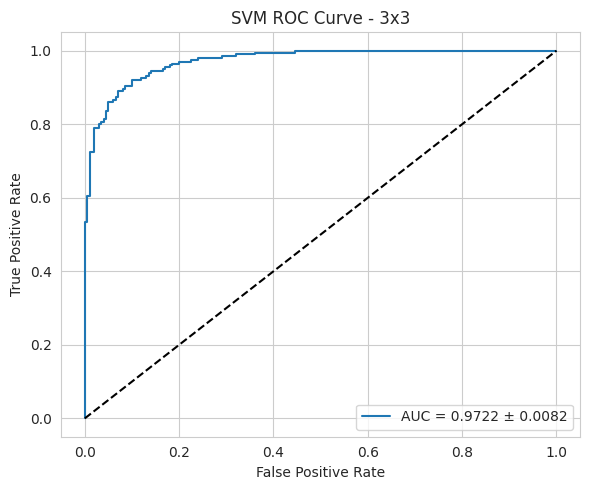

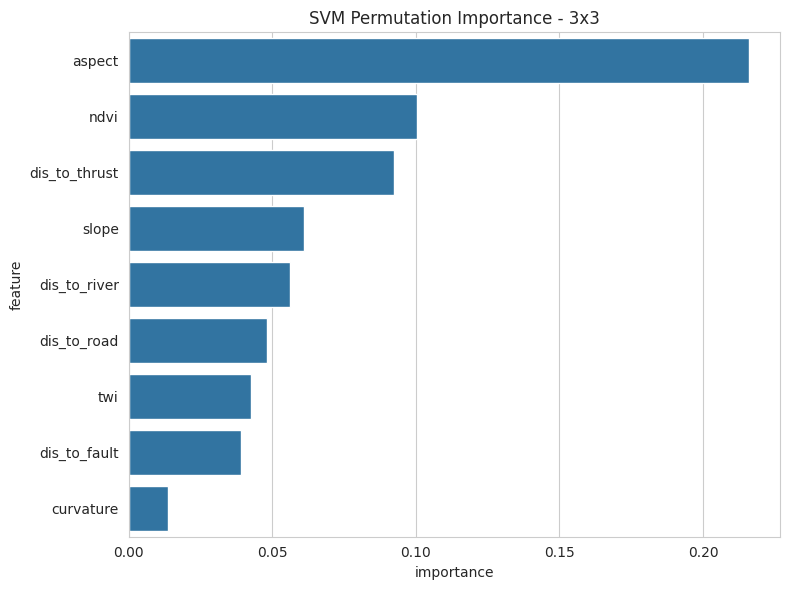

  0%|          | 0/100 [00:00<?, ?it/s]

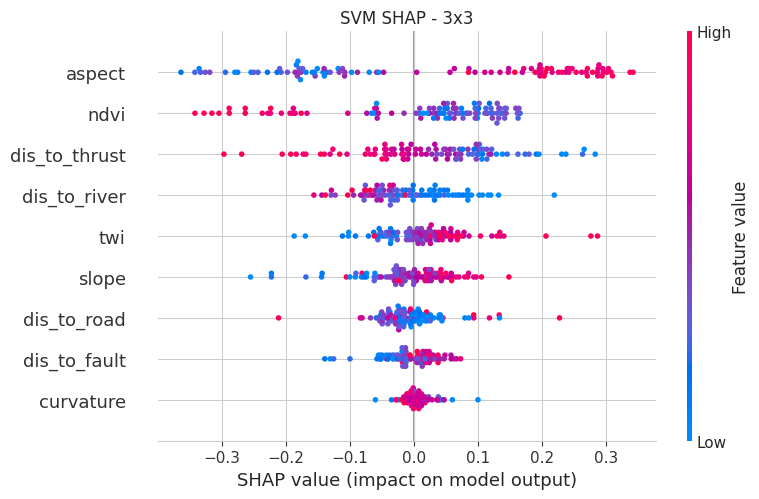


--------------- Training XGB on 3x3 ---------------
    Actual  Predicted  Probability
0        1          1     0.968124
1        1          1     0.967351
2        0          0     0.033034
3        0          0     0.031630
4        0          0     0.031354
5        1          1     0.966096
6        0          0     0.031210
7        0          0     0.031134
8        1          0     0.071806
9        1          1     0.955092
10       1          1     0.966926
11       1          1     0.968140
12       1          1     0.775442
13       1          1     0.968146
14       1          1     0.968106
15       1          1     0.963580
16       1          1     0.967982
17       1          1     0.968103
18       1          1     0.965640
19       1          1     0.967384
XGB Best Params: OrderedDict({'colsample_bytree': 0.7640415835413256, 'learning_rate': 0.11883357504897696, 'max_depth': 11, 'n_estimators': 229, 'subsample': 0.8680591793075738})
XGB Holdout Metrics: {'accuracy'

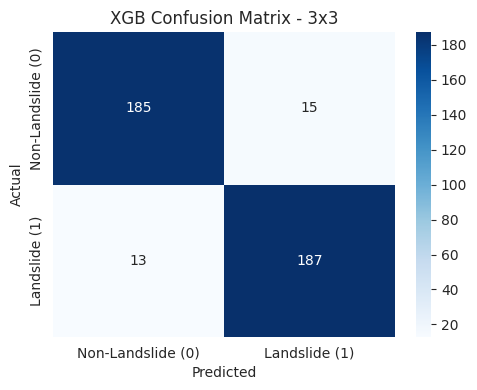

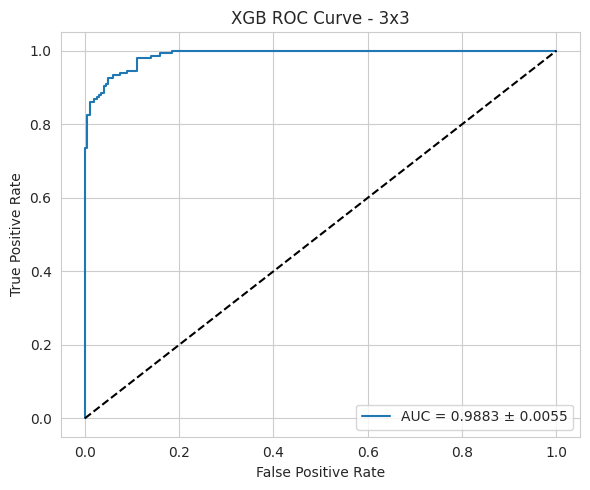

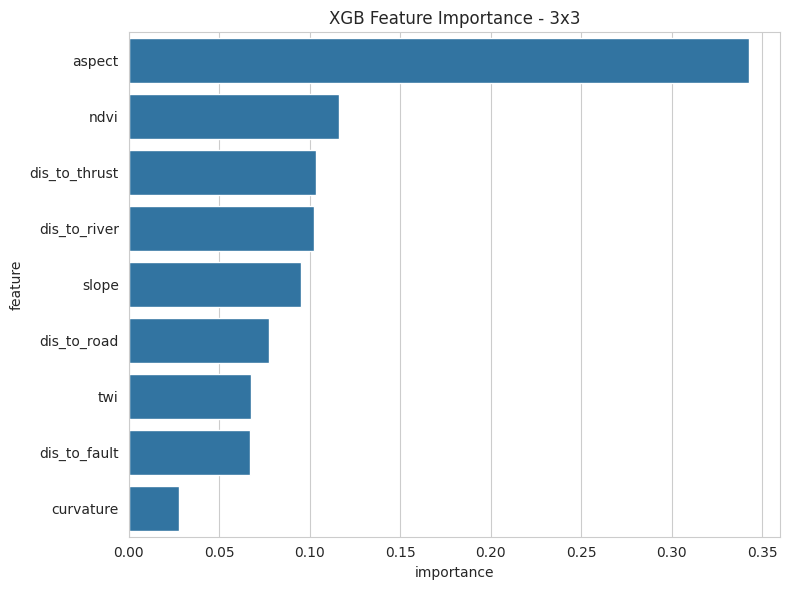

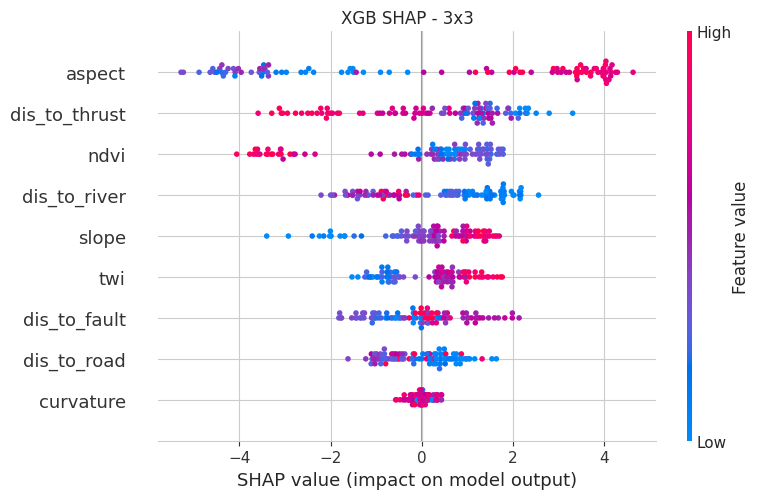


--------------- Ensemble on 3x3 ---------------
Ensemble Metrics: {'accuracy': 0.935, 'precision': 0.9438775510204082, 'recall': 0.925, 'f1': 0.9343434343434344, 'auc': 0.985175}
Ensemble Confusion Matrix:
 [[189  11]
 [ 15 185]]
              precision    recall  f1-score   support

           0     0.9265    0.9450    0.9356       200
           1     0.9439    0.9250    0.9343       200

    accuracy                         0.9350       400
   macro avg     0.9352    0.9350    0.9350       400
weighted avg     0.9352    0.9350    0.9350       400



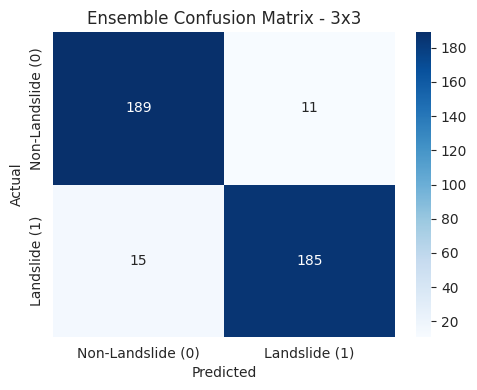

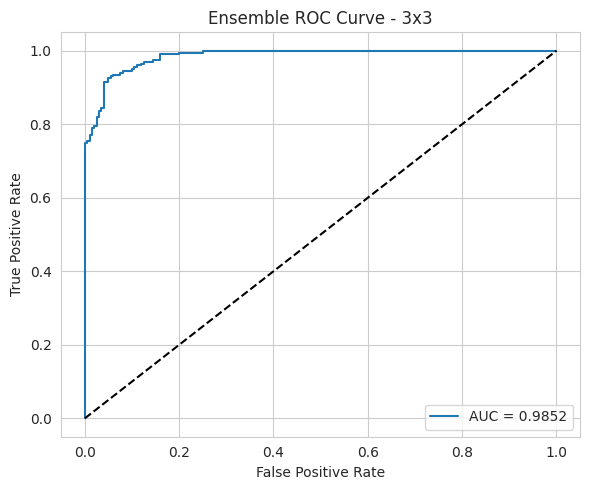

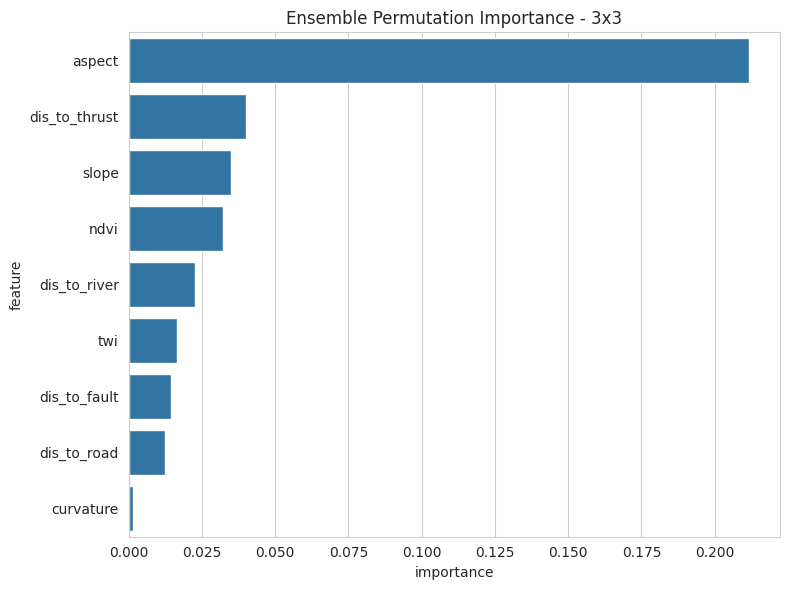

  0%|          | 0/100 [00:00<?, ?it/s]

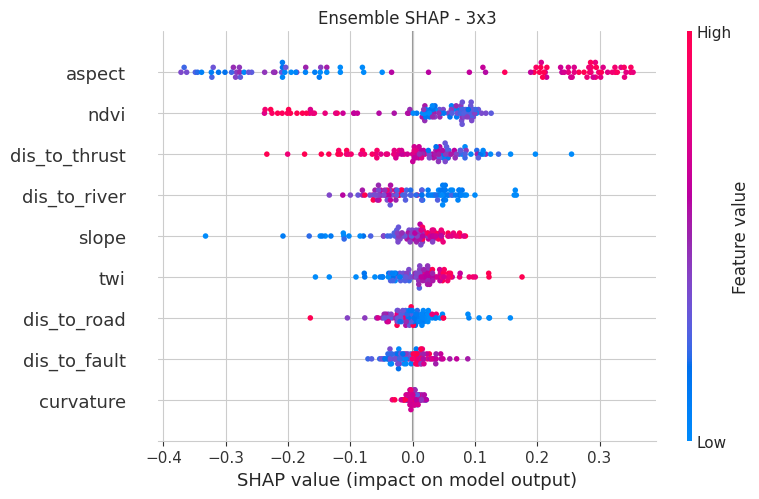


Completed grid: 3x3
  grid     model  accuracy  precision  recall        f1       auc  \
0  3x3        RF    0.9250   0.925000   0.925  0.925000  0.984500   
1  3x3       SVM    0.9025   0.900498   0.905  0.902743  0.972175   
2  3x3       XGB    0.9300   0.925743   0.935  0.930348  0.988275   
3  3x3  Ensemble    0.9350   0.943878   0.925  0.934343  0.985175   

   cv_auc_mean  cv_auc_std      cv_auc_text  \
0     0.985770    0.006125  0.9858 ± 0.0061   
1     0.976519    0.008184  0.9765 ± 0.0082   
2     0.989539    0.005542  0.9895 ± 0.0055   
3          NaN         NaN              NaN   

                                          model_path  
0  /content/drive/MyDrive/RemoteSensingResearchRe...  
1  /content/drive/MyDrive/RemoteSensingResearchRe...  
2  /content/drive/MyDrive/RemoteSensingResearchRe...  
3  /content/drive/MyDrive/RemoteSensingResearchRe...  

========================= GRID: 15x15 =========================

Shape: (1990, 10)
Class balance: [992 998]
Features: ['a

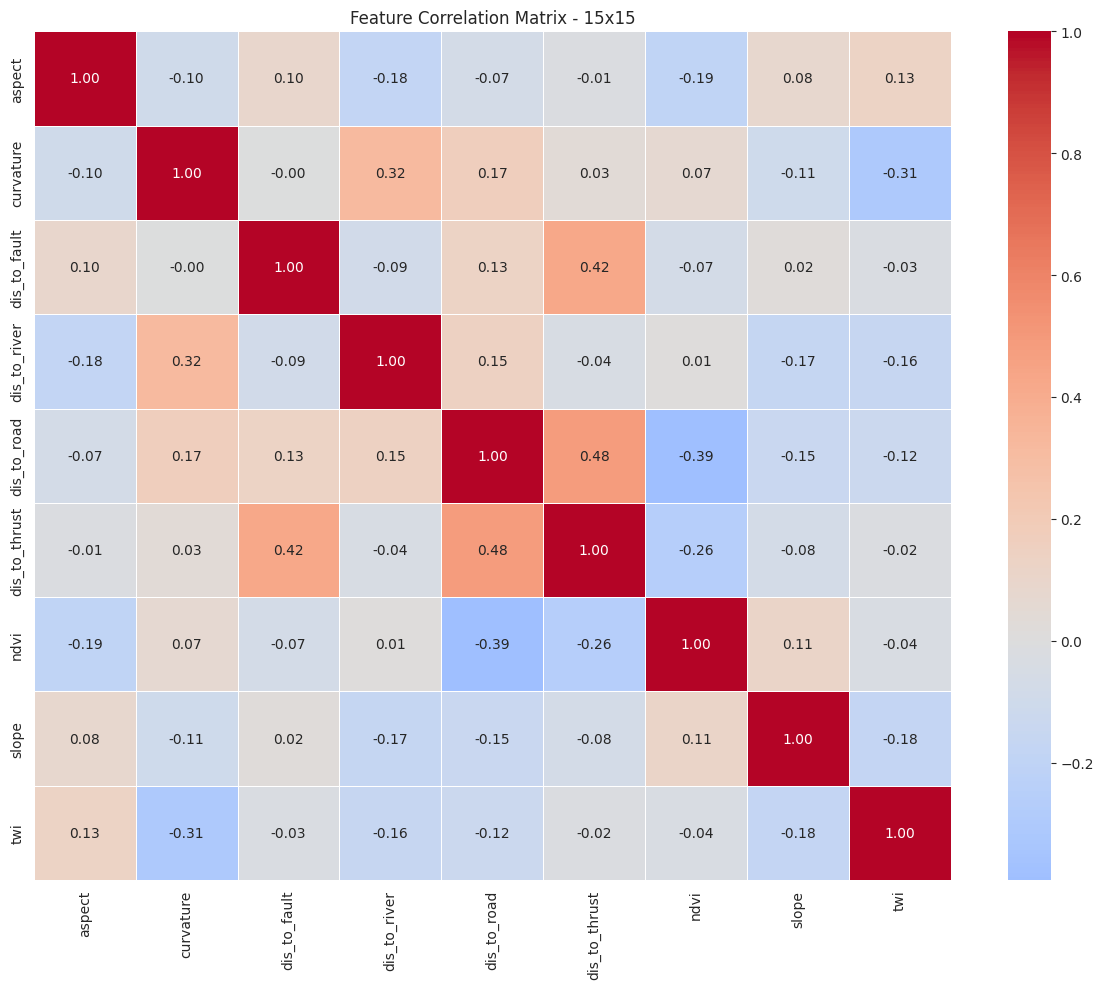

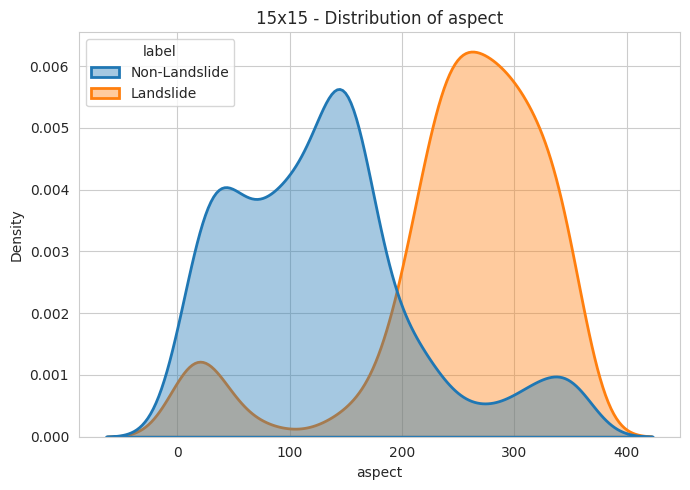

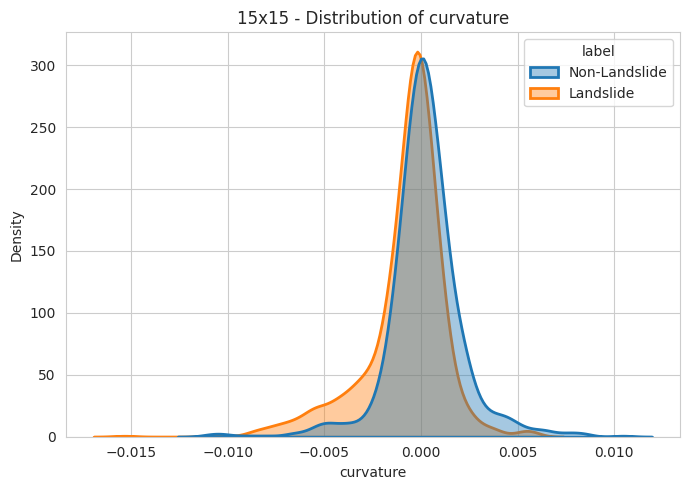

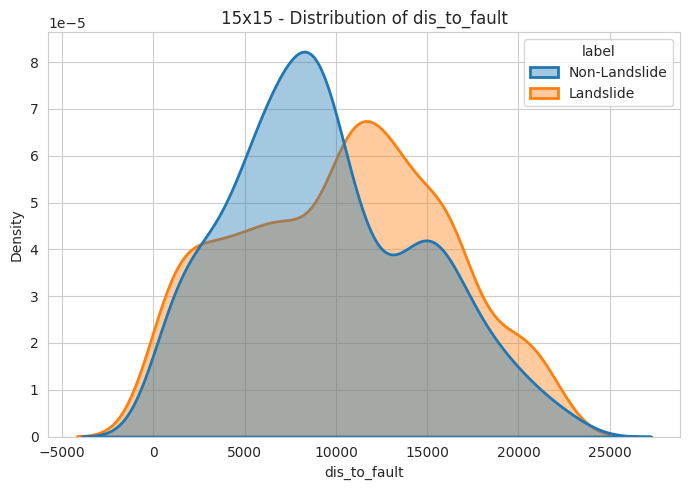

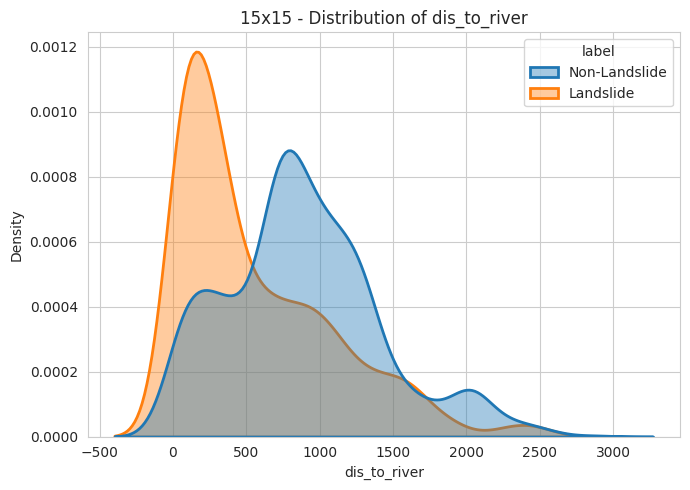

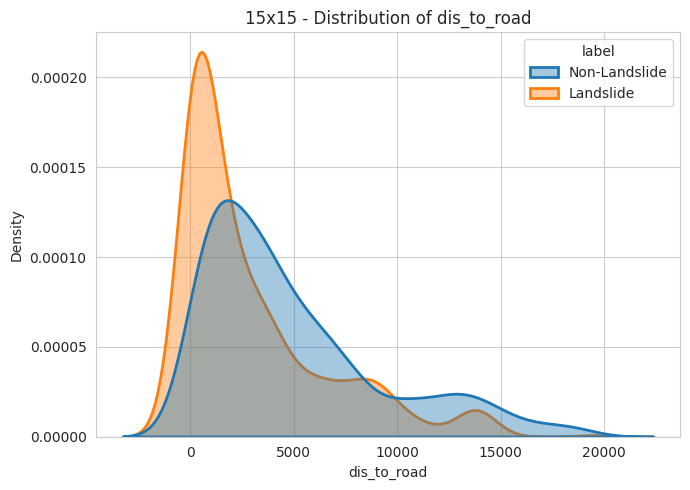

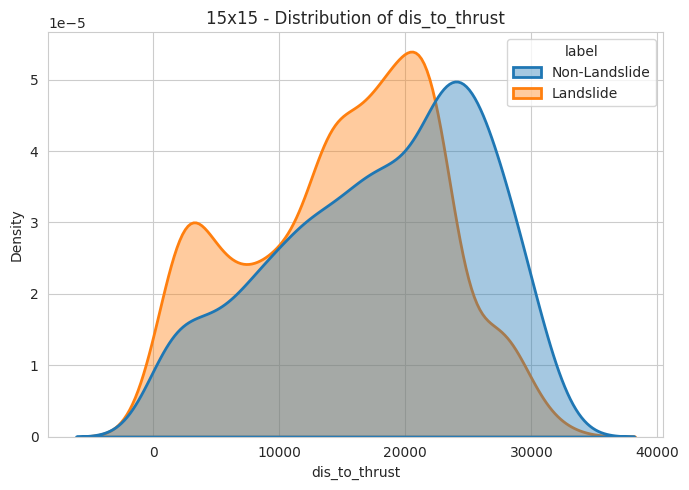

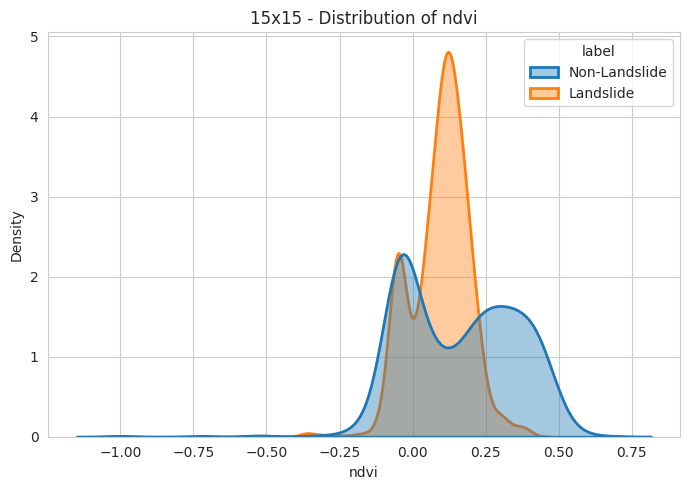

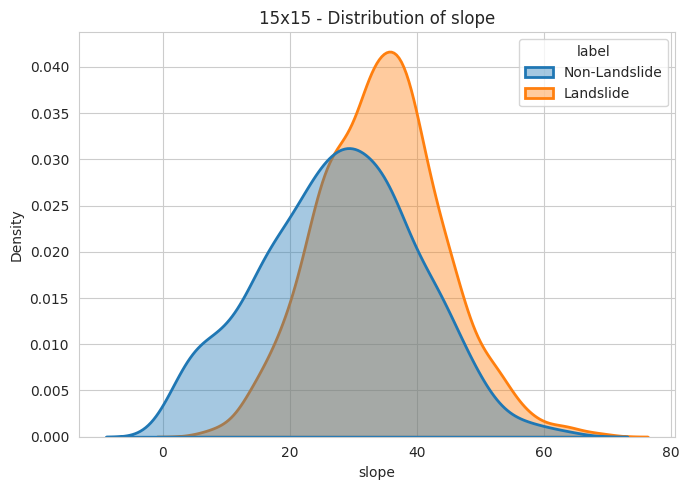

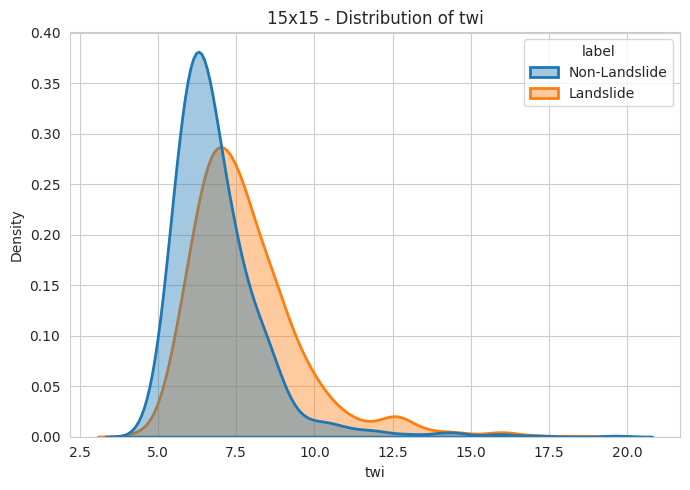


--------------- Training RF on 15x15 ---------------
    Actual  Predicted  Probability
0        0          0     0.015282
1        0          0     0.038900
2        1          1     0.989551
3        1          1     0.988502
4        0          0     0.013986
5        0          0     0.019547
6        0          0     0.012857
7        1          1     0.908783
8        1          1     0.990473
9        0          0     0.014686
10       1          1     0.974655
11       1          1     0.990327
12       0          0     0.013269
13       0          0     0.023797
14       0          0     0.015906
15       0          0     0.038547
16       0          0     0.019323
17       0          0     0.017295
18       1          1     0.976606
19       0          0     0.266259
RF Best Params: OrderedDict({'class_weight': 'balanced', 'max_depth': 25, 'min_samples_leaf': 2, 'min_samples_split': 7, 'n_estimators': 150})
RF Holdout Metrics: {'accuracy': 0.9522613065326633, 'precision': 0.

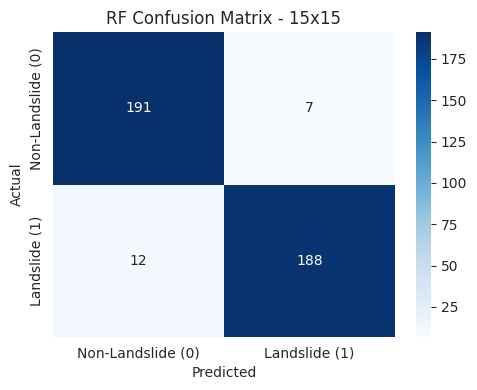

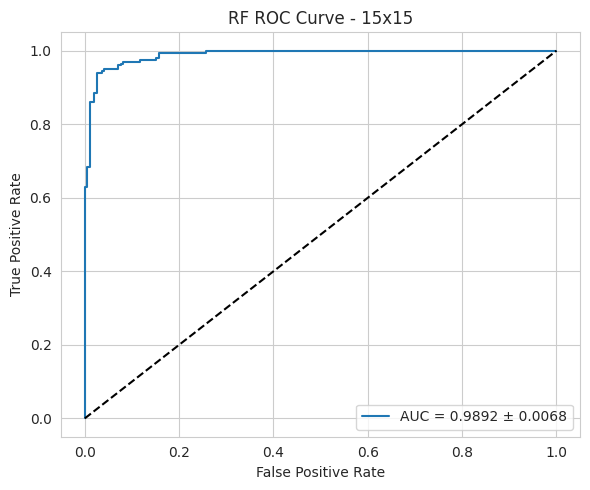

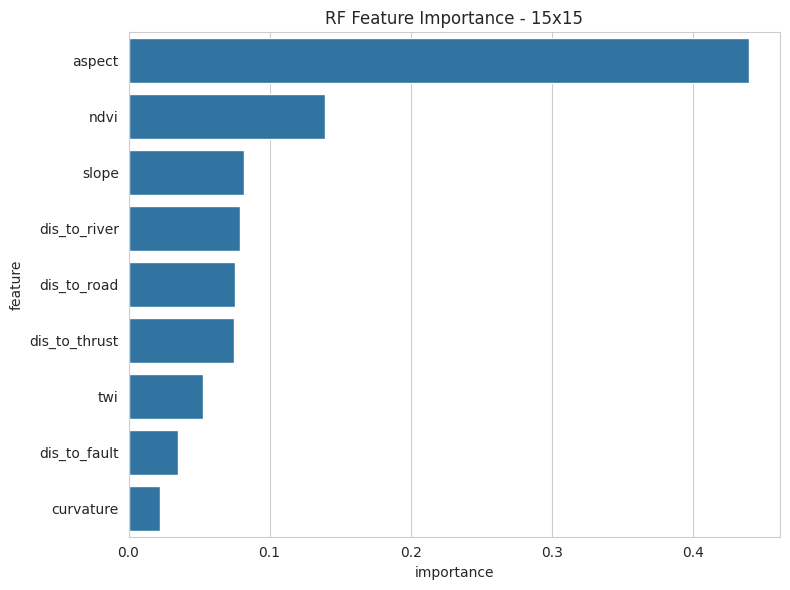

<Figure size 640x480 with 0 Axes>

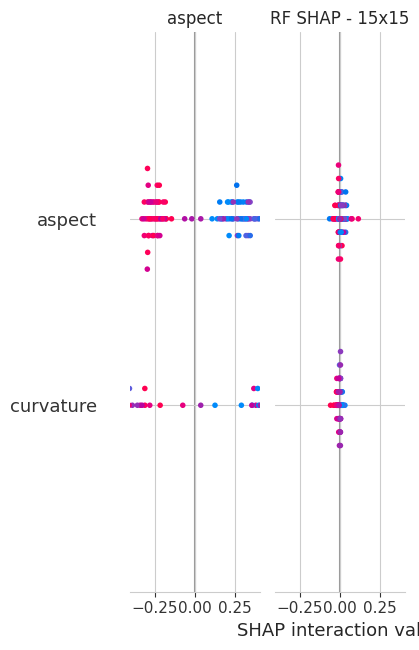


--------------- Training SVM on 15x15 ---------------
    Actual  Predicted  Probability
0        0          0     0.035930
1        0          0     0.050056
2        1          1     0.998759
3        1          1     0.943276
4        0          0     0.009383
5        0          0     0.033968
6        0          0     0.002821
7        1          1     0.639822
8        1          1     0.998818
9        0          0     0.004568
10       1          1     0.901924
11       1          1     0.999928
12       0          0     0.000811
13       0          0     0.222023
14       0          0     0.047185
15       0          0     0.113989
16       0          0     0.029271
17       0          0     0.009019
18       1          1     0.964038
19       0          0     0.172104
SVM Best Params: OrderedDict({'model__C': 2.9397976202716882, 'model__gamma': 0.4489379023123383, 'model__kernel': 'rbf'})
SVM Holdout Metrics: {'accuracy': 0.9422110552763819, 'precision': 0.9317073170731708, 

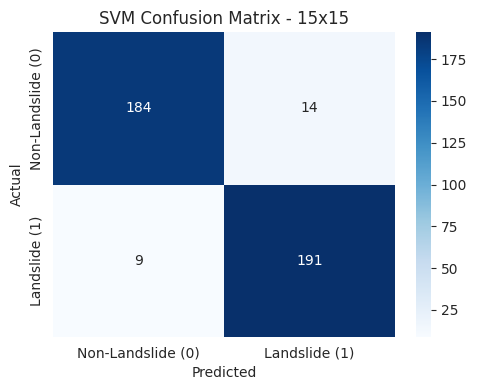

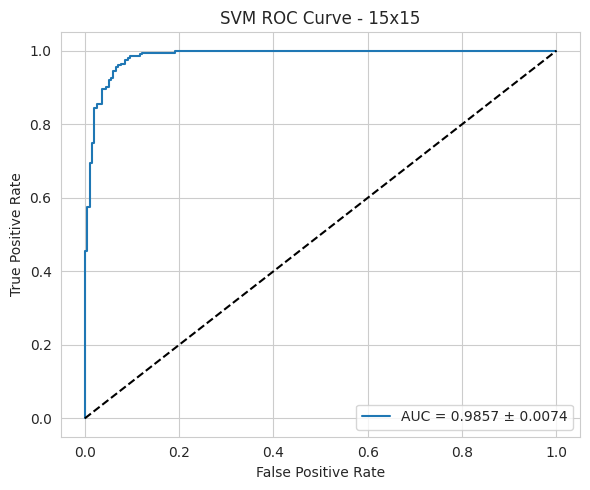

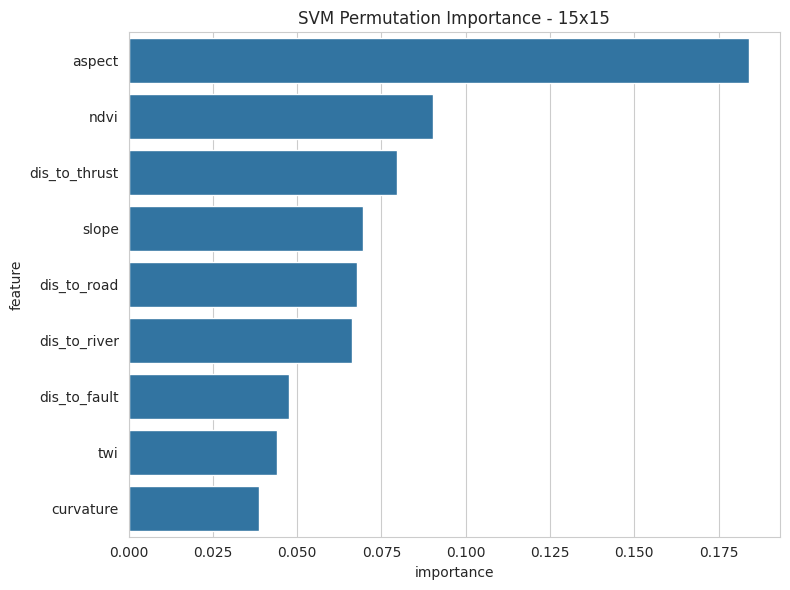

  0%|          | 0/100 [00:00<?, ?it/s]

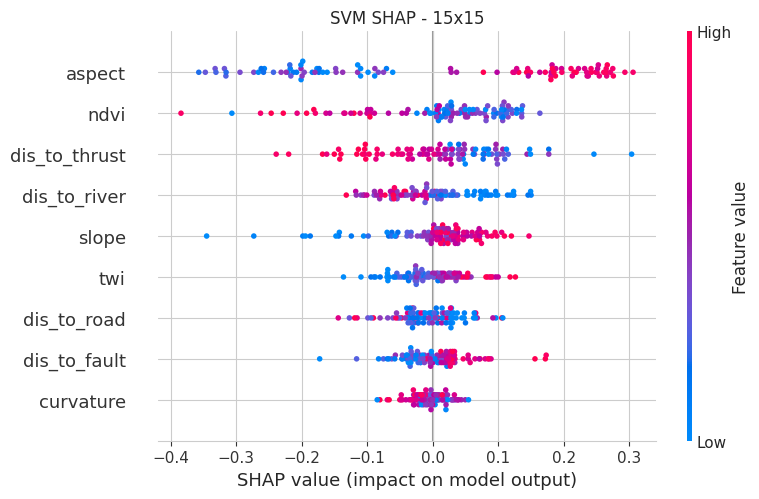


--------------- Training XGB on 15x15 ---------------


In [ ]:
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

drive.mount('/content/drive')

# ==========================================
# 2. PATHS
# ==========================================
excel_path = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/Filtered_Excel files/"
excel_files = {
    "3x3": "ls_non_ls_final_3x3",
    "15x15": "ls_non_ls_final_15x15",
    "25x25": "ls_non_ls_final_25x25"
}

base_output_dir = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/model_outputs"
os.makedirs(base_output_dir, exist_ok=True)

# ==========================================
# 3. SETTINGS
# ==========================================
RANDOM_STATE = 42
TEST_SIZE = 0.2
INNER_CV_SPLITS = 10
OUTER_CV_SPLITS = 10
BAYES_N_ITER = 20

# SHAP sampling controls
SHAP_BACKGROUND_SIZE = 100
SHAP_EXPLAIN_SIZE = 100

# ==========================================
# 4. HELPERS
# ==========================================
def make_dir(path):
    os.makedirs(path, exist_ok=True)

def sanitize_columns(df):
    df.columns = df.columns.str.strip()
    return df

def plot_correlation_matrix(df, save_path, title):
    plt.figure(figsize=(12, 10))
    corr = df.corr(numeric_only=True)
    sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def plot_distributions_by_class(df, features, target_col, out_dir, grid_name):
    dist_dir = os.path.join(out_dir, "distribution_plots")
    os.makedirs(dist_dir, exist_ok=True)

    df_plot = df.copy()
    df_plot['label'] = df_plot[target_col].map({0: 'Non-Landslide', 1: 'Landslide'})

    for col in features:
        plt.figure(figsize=(7,5))
        sns.kdeplot(
            data=df_plot,
            x=col,
            hue='label',
            fill=True,
            common_norm=False,   # 🔥 important
            alpha=0.4,
            linewidth=2
        )

        plt.title(f"{grid_name} - Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Density")

        plt.tight_layout()
        plt.savefig(os.path.join(dist_dir, f"{col}_distribution.png"), dpi=300)
        plt.show()
        plt.close()

def save_confusion_matrix(cm, labels, title, save_path):
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def save_roc_curve(y_true, y_prob, title, save_path, auc_mean=None, auc_std=None):
    from sklearn.metrics import roc_curve, auc

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_score = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))

    # ✅ Use mean ± std if provided
    if auc_mean is not None and auc_std is not None:
        label_text = f"AUC = {auc_score:.4f} \u00B1 {auc_std:.4f}"
    else:
        label_text = f"AUC = {auc_score:.4f}"

    plt.plot(fpr, tpr, label=label_text)
    plt.plot([0, 1], [0, 1], "k--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def compute_metrics(y_true, y_pred, y_prob):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "auc": float(roc_auc_score(y_true, y_prob))
    }
def compute_cv_auc_stats(estimator, X, y, n_splits=5, random_state=42):
    outer_cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    auc_scores = cross_val_score(
        estimator,
        X,
        y,
        cv=outer_cv,
        scoring="roc_auc",
        n_jobs=-1
    )
    return float(np.mean(auc_scores)), float(np.std(auc_scores)), auc_scores

def plot_calibration_comparison(model, calibrated_model, X_test, y_test, grid_name, model_name, save_dir):
    from sklearn.metrics import roc_auc_score
    import matplotlib.pyplot as plt
    import seaborn as sns
    import os

    # Raw probabilities (before calibration)
    raw_prob = model.predict_proba(X_test)[:, 1]

    # Calibrated probabilities
    cal_prob = calibrated_model.predict_proba(X_test)[:, 1]

    # Compute AUCs
    auc_raw = roc_auc_score(y_test, raw_prob)
    auc_cal = roc_auc_score(y_test, cal_prob)

    # Plot distributions
    plt.figure(figsize=(7, 5))

    sns.kdeplot(raw_prob, label=f"Before (AUC={auc_raw:.2f})", linewidth=2)
    sns.kdeplot(cal_prob, label=f"After (AUC={auc_cal:.2f})", linewidth=2)

    plt.title(f"{model_name} Calibration Comparison - {grid_name}")
    plt.xlabel("Predicted Probability")
    plt.ylabel("Density")
    plt.legend()

    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{model_name}_{grid_name}_calibration.png"), dpi=300)
    plt.show()
    plt.close()

def get_feature_names_from_estimator(estimator, X_columns):
    if hasattr(estimator, "feature_names_in_"):
        return list(estimator.feature_names_in_)
    return list(X_columns)

def plot_feature_importance(importances, feature_names, title, save_path, top_n=15):
    imp_df = pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    }).sort_values("importance", ascending=False).head(top_n)

    plt.figure(figsize=(8, 6))
    sns.barplot(data=imp_df, x="importance", y="feature")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    return imp_df

def get_native_importance(model_name, fitted_estimator, X_train, y_train):
    # For calibrated models, the real fitted estimator is in calibrated_classifiers_[i].estimator
    # but easiest stable source is base_estimator used before calibration when possible.
    if model_name == "RF":
        return fitted_estimator.feature_importances_
    elif model_name == "XGB":
        return fitted_estimator.feature_importances_
    elif model_name == "SVM":
        perm = permutation_importance(
            fitted_estimator, X_train, y_train,
            scoring="f1", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
        )
        return perm.importances_mean
    else:
        raise ValueError("Unknown model name")

def ensemble_predict_proba(model_dict, X):
    probs = []
    for _, model in model_dict.items():
        probs.append(model.predict_proba(X)[:, 1])
    return np.mean(np.column_stack(probs), axis=1)

def plot_shap_tree(model, X_sample, title, save_prefix):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_sample)

    # Binary classification sometimes returns list, sometimes array
    if isinstance(shap_values, list):
        shap_plot_values = shap_values[1]
    else:
        shap_plot_values = shap_values

    plt.figure()
    shap.summary_plot(shap_plot_values, X_sample, show=False)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_shap_summary.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def plot_shap_kernel(model, X_background, X_sample, title, save_prefix):
    # Slow, so use small samples
    predict_fn = lambda data: model.predict_proba(pd.DataFrame(data, columns=X_sample.columns))[:, 1]

    explainer = shap.KernelExplainer(
        predict_fn,
        shap.sample(X_background, min(len(X_background), SHAP_BACKGROUND_SIZE), random_state=RANDOM_STATE)
    )
    shap_values = explainer.shap_values(
        shap.sample(X_sample, min(len(X_sample), SHAP_EXPLAIN_SIZE), random_state=RANDOM_STATE),
        nsamples=100
    )

    X_used = shap.sample(X_sample, min(len(X_sample), SHAP_EXPLAIN_SIZE), random_state=RANDOM_STATE)

    plt.figure()
    shap.summary_plot(shap_values, X_used, show=False)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_shap_summary.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def plot_ensemble_permutation_importance(models_dict, X_test, y_test, save_path, title):
    # Permutation importance for ensemble using its averaged probability
    baseline_prob = ensemble_predict_proba(models_dict, X_test)
    baseline_pred = (baseline_prob >= 0.5).astype(int)
    baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

    importances = []
    X_temp = X_test.copy()

    rng = np.random.default_rng(RANDOM_STATE)

    for col in X_test.columns:
        scores = []
        for _ in range(10):
            X_perm = X_temp.copy()
            X_perm[col] = rng.permutation(X_perm[col].values)
            prob = ensemble_predict_proba(models_dict, X_perm)
            pred = (prob >= 0.5).astype(int)
            score = f1_score(y_test, pred, zero_division=0)
            scores.append(baseline_f1 - score)
        importances.append(np.mean(scores))

    return plot_feature_importance(
        np.array(importances),
        list(X_test.columns),
        title=title,
        save_path=save_path
    )
def prediction_table(y_test, y_pred, y_prob):
  # Create results table
  results_df = pd.DataFrame({
      "Actual": y_test,
      "Predicted": y_pred,
      "Probability": y_prob
  })

  # Reset index for clean display
  results_df = results_df.reset_index(drop=True)

  # Show first few rows
  print(results_df.head(20))
def plot_ensemble_shap(models_dict, X_train, X_test, save_prefix, title):
    X_bg = shap.sample(X_train, min(len(X_train), SHAP_BACKGROUND_SIZE), random_state=RANDOM_STATE)
    X_explain = shap.sample(X_test, min(len(X_test), SHAP_EXPLAIN_SIZE), random_state=RANDOM_STATE)

    predict_fn = lambda data: ensemble_predict_proba(
        models_dict,
        pd.DataFrame(data, columns=X_test.columns)
    )

    explainer = shap.KernelExplainer(predict_fn, X_bg)
    shap_values = explainer.shap_values(X_explain, nsamples=100)

    plt.figure()
    shap.summary_plot(shap_values, X_explain, show=False)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_shap_summary.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def save_json(data, path):
    with open(path, "w") as f:
        json.dump(data, f, indent=4)

# ==========================================
# 5. MODELS + SEARCH SPACES
# ==========================================
models = {
    "RF": RandomForestClassifier(random_state=RANDOM_STATE),
    "SVM": SVC(probability=True, class_weight='balanced', random_state=RANDOM_STATE),
    "XGB": XGBClassifier(
        eval_metric='logloss',
        random_state=RANDOM_STATE,
        use_label_encoder=False
    )
}

param_spaces = {
    "RF": {
        'n_estimators': Integer(150, 400),
        'max_depth': Integer(5, 25),
        'min_samples_split': Integer(2, 10),
        'min_samples_leaf': Integer(1, 10),
        'class_weight': Categorical(['balanced', 'balanced_subsample'])
    },
    "SVM": {
        'model__C': Real(1e-2, 100, prior='log-uniform'),
        'model__gamma': Real(1e-5, 10, prior='log-uniform'),
        'model__kernel': Categorical(['rbf'])
    },
    "XGB": {
        'n_estimators': Integer(150, 400),
        'max_depth': Integer(3, 12),
        'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
        'subsample': Real(0.6, 1.0),
        'colsample_bytree': Real(0.6, 1.0)
    }
}

# ==========================================
# 6. LOOP OVER ALL GRIDS
# ==========================================
all_grid_summary = []

for grid, file in excel_files.items():
    print(f"\n{'='*25} GRID: {grid} {'='*25}\n")

    # --------------------------------------
    # Paths for this grid
    # --------------------------------------
    grid_out_dir = os.path.join(base_output_dir, grid)
    make_dir(grid_out_dir)
    make_dir(os.path.join(grid_out_dir, "models"))
    make_dir(os.path.join(grid_out_dir, "plots"))
    make_dir(os.path.join(grid_out_dir, "plots", "roc"))
    make_dir(os.path.join(grid_out_dir, "plots", "cm"))
    make_dir(os.path.join(grid_out_dir, "plots", "importance"))
    make_dir(os.path.join(grid_out_dir, "plots", "shap"))

    # --------------------------------------
    # Load data
    # --------------------------------------
    df = pd.read_excel(f"{excel_path}{file}.xlsx")
    df = sanitize_columns(df)

    # keep original for plotting if needed
    df = df.drop(["ndwi", "roughness", "X", "Y"], axis=1, errors='ignore')
    df = df.dropna().reset_index(drop=True)
    df_plot = df.copy()
    df_plot['Class'] = df_plot['ID'].map({0: 'Non-Landslide', 1: 'Landslide'})
    y = df["ID"].astype(int).values
    X = df.drop(columns=["ID"]).copy()

    print("Shape:", df.shape)
    print("Class balance:", np.bincount(y))
    print("Features:", list(X.columns))

    # --------------------------------------
    # EDA
    # --------------------------------------
    plot_correlation_matrix(
        X,
        save_path=os.path.join(grid_out_dir, "plots", f"{grid}_correlation_matrix.png"),
        title=f"Feature Correlation Matrix - {grid}"
    )

    plot_distributions_by_class(
        df=pd.concat([X, pd.Series(y, name="ID")], axis=1),
        features=X.columns,
        target_col="ID",
        out_dir=os.path.join(grid_out_dir, "plots"),
        grid_name=grid
    )

    # --------------------------------------
    # Train-test split
    # --------------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y
    )

    inner_cv = StratifiedKFold(n_splits=INNER_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

    fitted_models = {}
    grid_results = []

    # ======================================
    # 7. TRAIN RF, SVM, XGB
    # ======================================
    for name, model in models.items():
        print(f"\n{'-'*15} Training {name} on {grid} {'-'*15}")

        if name == "SVM":
            estimator = Pipeline([
                ("scaler", StandardScaler()),
                ("model", model)
            ])
            search_space = param_spaces[name]
        else:
            estimator = model
            search_space = param_spaces[name]

        search = BayesSearchCV(
            estimator=estimator,
            search_spaces=search_space,
            n_iter=BAYES_N_ITER,
            cv=inner_cv,
            scoring='f1',
            n_jobs=-1,
            random_state=RANDOM_STATE,
            refit=True
        )

        search.fit(X_train, y_train)

        # same idea as your provided code: BayesSearchCV -> calibration
        calibrated = CalibratedClassifierCV(search.best_estimator_, cv=3)
        calibrated.fit(X_train, y_train)
    #     plot_calibration_comparison(
    #     model=search.best_estimator_,
    #     calibrated_model=calibrated,
    #     X_test=X_test,
    #     y_test=y_test,
    #     grid_name=grid,
    #     model_name=name,
    #     save_dir=os.path.join(grid_out_dir, "plots")
    # )
        # holdout test metrics
        y_pred = calibrated.predict(X_test)
        y_prob = calibrated.predict_proba(X_test)[:, 1]
        prediction_table(y_test, y_pred, y_prob)
        metrics_dict = compute_metrics(y_test, y_pred, y_prob)
        cm = confusion_matrix(y_test, y_pred)

        # cross-validated AUC mean ± std on full dataset using tuned estimator
        if name == "SVM":
            best_estimator_for_cv = CalibratedClassifierCV(search.best_estimator_, cv=3)
        else:
            best_estimator_for_cv = CalibratedClassifierCV(search.best_estimator_, cv=3)

        mean_auc_cv, std_auc_cv, auc_scores_cv = compute_cv_auc_stats(
            best_estimator_for_cv,
            X_train,
            y_train,
            n_splits=OUTER_CV_SPLITS,
            random_state=RANDOM_STATE
        )

        print(f"{name} Best Params: {search.best_params_}")
        print(f"{name} Holdout Metrics: {metrics_dict}")
        print(f"{name} CV AUC: {mean_auc_cv:.4f} \u00B1 {std_auc_cv:.4f}")
        print(f"{name} Fold-wise AUCs: {np.round(auc_scores_cv, 4)}")
        print("Confusion Matrix:\n", cm)
        print(classification_report(y_test, y_pred, digits=4))

        # save plots
        save_confusion_matrix(
            cm,
            labels=["Non-Landslide (0)", "Landslide (1)"],
            title=f"{name} Confusion Matrix - {grid}",
            save_path=os.path.join(grid_out_dir, "plots", "cm", f"{name}_{grid}_cm.png")
        )

        save_roc_curve(
            y_test,
            y_prob,
            title=f"{name} ROC Curve - {grid}",
            save_path=os.path.join(grid_out_dir, "plots", "roc", f"{name}_{grid}_roc.png"),
            auc_mean=mean_auc_cv,
            auc_std=std_auc_cv
        )

        # feature importance
        if name == "RF":
            fitted_base = search.best_estimator_
            importances = get_native_importance(name, fitted_base, X_train, y_train)
            imp_df = plot_feature_importance(
                importances,
                X.columns,
                title=f"{name} Feature Importance - {grid}",
                save_path=os.path.join(grid_out_dir, "plots", "importance", f"{name}_{grid}_importance.png")
            )
            plot_shap_tree(
                fitted_base,
                shap.sample(X_test, min(len(X_test), SHAP_EXPLAIN_SIZE), random_state=RANDOM_STATE),
                title=f"{name} SHAP - {grid}",
                save_prefix=os.path.join(grid_out_dir, "plots", "shap", f"{name}_{grid}")
            )

        elif name == "XGB":
            fitted_base = search.best_estimator_
            importances = get_native_importance(name, fitted_base, X_train, y_train)
            imp_df = plot_feature_importance(
                importances,
                X.columns,
                title=f"{name} Feature Importance - {grid}",
                save_path=os.path.join(grid_out_dir, "plots", "importance", f"{name}_{grid}_importance.png")
            )
            plot_shap_tree(
                fitted_base,
                shap.sample(X_test, min(len(X_test), SHAP_EXPLAIN_SIZE), random_state=RANDOM_STATE),
                title=f"{name} SHAP - {grid}",
                save_prefix=os.path.join(grid_out_dir, "plots", "shap", f"{name}_{grid}")
            )

        elif name == "SVM":
            fitted_base = search.best_estimator_
            importances = get_native_importance(name, fitted_base, X_train, y_train)
            imp_df = plot_feature_importance(
                importances,
                X.columns,
                title=f"{name} Permutation Importance - {grid}",
                save_path=os.path.join(grid_out_dir, "plots", "importance", f"{name}_{grid}_importance.png")
            )
            plot_shap_kernel(
                fitted_base,
                X_train,
                X_test,
                title=f"{name} SHAP - {grid}",
                save_prefix=os.path.join(grid_out_dir, "plots", "shap", f"{name}_{grid}")
            )

        else:
            imp_df = None

        # save model
        model_path = os.path.join(grid_out_dir, "models", f"{name}_{grid}_calibrated.pkl")
        joblib.dump(calibrated, model_path)

        # save best params
        params_path = os.path.join(grid_out_dir, "models", f"{name}_{grid}_best_params.json")
        save_json(search.best_params_, params_path)

        fitted_models[name] = calibrated

        row = {
            "grid": grid,
            "model": name,
            **metrics_dict,
            "cv_auc_mean": mean_auc_cv,
            "cv_auc_std": std_auc_cv,
            "cv_auc_text": f"{mean_auc_cv:.4f} \u00B1 {std_auc_cv:.4f}",
            "model_path": model_path
        }
        grid_results.append(row)

        gc.collect()

    # ======================================
    # 8. ENSEMBLE
    # ======================================
    print(f"\n{'-'*15} Ensemble on {grid} {'-'*15}")

    ensemble_prob = ensemble_predict_proba(fitted_models, X_test)
    ensemble_pred = (ensemble_prob >= 0.5).astype(int)

    ensemble_metrics = compute_metrics(y_test, ensemble_pred, ensemble_prob)
    ensemble_cm = confusion_matrix(y_test, ensemble_pred)

    print("Ensemble Metrics:", ensemble_metrics)
    print("Ensemble Confusion Matrix:\n", ensemble_cm)
    print(classification_report(y_test, ensemble_pred, digits=4))

    save_confusion_matrix(
        ensemble_cm,
        labels=["Non-Landslide (0)", "Landslide (1)"],
        title=f"Ensemble Confusion Matrix - {grid}",
        save_path=os.path.join(grid_out_dir, "plots", "cm", f"Ensemble_{grid}_cm.png")
    )

    save_roc_curve(
        y_test, ensemble_prob,
        title=f"Ensemble ROC Curve - {grid}",
        save_path=os.path.join(grid_out_dir, "plots", "roc", f"Ensemble_{grid}_roc.png")
    )

    # ensemble importance
    ensemble_imp_df = plot_ensemble_permutation_importance(
        fitted_models,
        X_test,
        y_test,
        save_path=os.path.join(grid_out_dir, "plots", "importance", f"Ensemble_{grid}_importance.png"),
        title=f"Ensemble Permutation Importance - {grid}"
    )

    # ensemble shap
    plot_ensemble_shap(
        fitted_models,
        X_train,
        X_test,
        save_prefix=os.path.join(grid_out_dir, "plots", "shap", f"Ensemble_{grid}"),
        title=f"Ensemble SHAP - {grid}"
    )

    # save ensemble object
    ensemble_bundle = {
        "models": fitted_models,
        "features": list(X.columns),
        "threshold": 0.5,
        "method": "mean_probability"
    }
    ensemble_path = os.path.join(grid_out_dir, "models", f"Ensemble_{grid}.pkl")
    joblib.dump(ensemble_bundle, ensemble_path)

    grid_results.append({
        "grid": grid,
        "model": "Ensemble",
        **ensemble_metrics,
        "model_path": ensemble_path
    })

    # save per-grid summary
    grid_summary_df = pd.DataFrame(grid_results)
    grid_summary_df.to_csv(os.path.join(grid_out_dir, f"{grid}_model_summary.csv"), index=False)

    all_grid_summary.extend(grid_results)

    print(f"\nCompleted grid: {grid}")
    print(grid_summary_df)

    gc.collect()

# ==========================================
# 9. FINAL SUMMARY ACROSS ALL GRIDS
# ==========================================
final_summary_df = pd.DataFrame(all_grid_summary)
final_summary_path = os.path.join(base_output_dir, "all_grids_model_summary.csv")
final_summary_df.to_csv(final_summary_path, index=False)

print("\nFinal summary across all grids:")
print(final_summary_df)
print(f"\nSaved final summary to: {final_summary_path}")